# Применение условных вероятностей в анализе данных

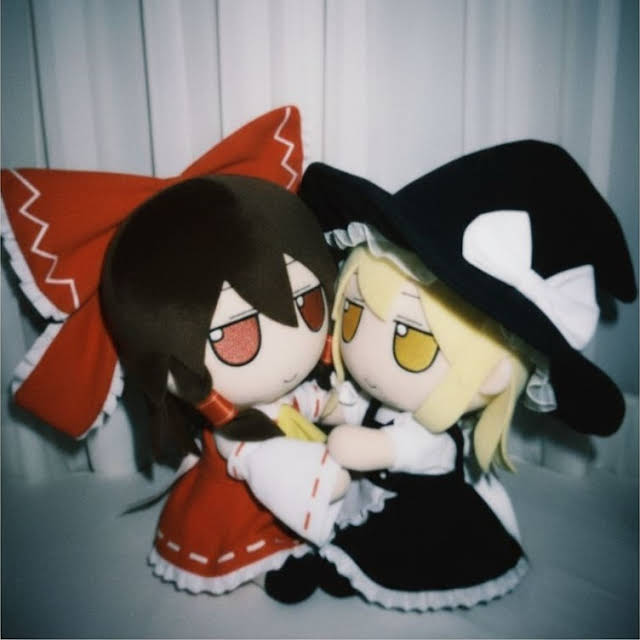

---

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('adult.csv')
print(f'Размерность:{df.shape}')

Размерность:(32561, 15)


## Описание набора данных

| Признак | Тип | Описание |
|---------|-----|----------|
| `age` | число | возраст, лет |
| `workclass` | категория | тип занятости |
| `fnlwgt` | число | итоговый вес |
| `education` | категория | образование |
| `education.num` | число | образование в виде числа (число лет обучения, порядковый номер ступени) |
| `marital.status` | категория | семейное положение |
| `occupation` | категория | профессия |
| `relationship` | категория | роль в семье |
| `race` | категория | раса |
| `sex` | категория | пол |
| `capital.gain` | число | доход от прироста капитала за год |
| `capital.loss` | число | потери капитала за год |
| `hours.per.week` | число | рабочих часов в неделю |
| `native.country` | категория | страна происхождения |
| `income` | цель | `<=50K` или `>50K` — годовой доход |

In [4]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [5]:
df.columns.to_list()

['age',
 'workclass',
 'fnlwgt',
 'education',
 'education.num',
 'marital.status',
 'occupation',
 'relationship',
 'race',
 'sex',
 'capital.gain',
 'capital.loss',
 'hours.per.week',
 'native.country',
 'income']

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [7]:
print('Пропущенные значения:')
pd.DataFrame({'Количество пропусков':(df == '?').sum()[lambda x: x > 0],
              'Процент пропусков':round(((df == '?').sum()[lambda x: x > 0] / len(df)) * 100, 2)})

Пропущенные значения:


,Количество пропусков,Процент пропусков
workclass,1836,5.64
occupation,1843,5.66
native.country,583,1.79


Вычислим априорную вероятность $H$ - доход выше 50 тысяч

In [8]:
P_H = (df['income'] == '>50K').sum() / len(df)
P_notH = 1 - P_H
print(f"P(H) = {P_H:.4f}")
print(f"P(не H) = {P_notH:.4f}")

P(H) = 0.2408
P(не H) = 0.7592


## Условная вероятность
### Найдем вероятность, что у человека доход больше 50 тысяч при условии, что у него то или иное образование
$$P_{A}(H) = \frac{P(H \cap A)}{P(A)}, \quad P(A) > 0.$$
Найдем изменение вероятности $H$ в зависимости от образования человека

In [9]:
df['edu_cat'] = pd.cut(df['education.num'], bins=[0, 8, 9, 12, 13, 16],
                       labels=['неполное среднее', 'среднее', 'колледж', 'бакалавр', 'магистр и выше'])
df['edu_cat'].value_counts() / len(df)

edu_cat
среднее             0.322502
колледж             0.299131
бакалавр            0.164461
неполное среднее    0.130616
магистр и выше      0.083290
Name: count, dtype: float64

Пусть событие $A$ - у человека есть какое-нибудь образование 

In [10]:
labels = ['неполное среднее', 'среднее', 'колледж', 'бакалавр', 'магистр и выше']

rows = []
for label in labels:
    p = ((df['edu_cat'] == label) & (df['income'] == '>50K')).mean()
    q = ((df['edu_cat'] == label) & (df['income'] == '<=50K')).mean()
    rows.append({'Образование': label, 'P(A * H)': p, 'P(A * не H)': q})

table = pd.DataFrame(rows).set_index('Образование')

table['P(A)'] = table['P(A * H)'] + table['P(A * не H)']
table['P(H | A)'] = table['P(A * H)'] / table['P(A)']
table

,P(A * H),P(A * не H),P(A),P(H | A)
Образование,,,,
неполное среднее,0.007494,0.123123,0.130616,0.057371
среднее,0.051442,0.271060,0.322502,0.159509
колледж,0.061822,0.237308,0.299131,0.206674
бакалавр,0.068210,0.096250,0.164461,0.414753
магистр и выше,0.051841,0.031449,0.083290,0.622419


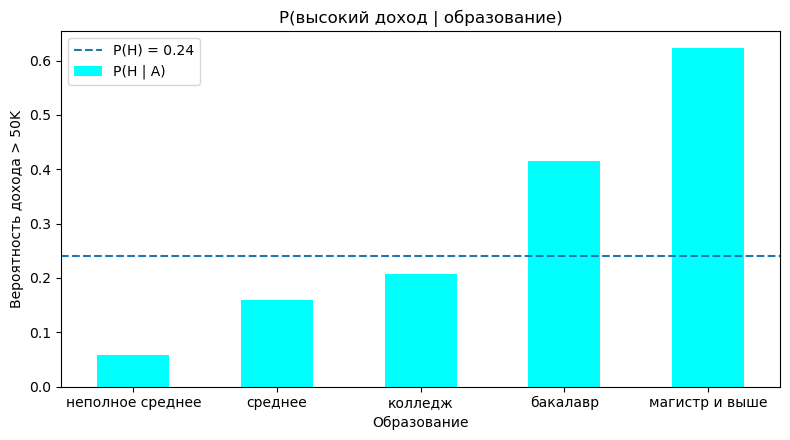

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))

table['P(H | A)'].plot(kind='bar', color='cyan', ax=ax)
ax.axhline(P_H, linestyle='--', label=f'P(H) = {P_H:.2f}')
ax.set_title('P(высокий доход | образование)')
ax.set_xlabel('Образование')
ax.set_ylabel('Вероятность дохода > 50K')
ax.tick_params(axis='x', rotation=0)
ax.legend()
plt.tight_layout()
plt.show()

### Найдем вероятность, что у человека доход больше 50 тысяч при условии, что он мужчина или женщина


In [12]:
rows = []
for sex in df['sex'].unique():
    p = ((df['sex'] == sex) & (df['income'] == '>50K')).mean()
    q = ((df['sex'] == sex) & (df['income'] == '<=50K')).mean()
    rows.append({'Пол': sex, 'P(A * H)': p, 'P(A * не H)': q})

table = pd.DataFrame(rows).set_index('Пол')

table['P(A)'] = table['P(A * H)'] + table['P(A * не H)']
table['P(H | A)'] = table['P(A * H)'] / table['P(A)']
table

,P(A * H),P(A * не H),P(A),P(H | A)
Пол,,,,
Female,0.036209,0.294586,0.330795,0.109461
Male,0.204601,0.464605,0.669205,0.305737


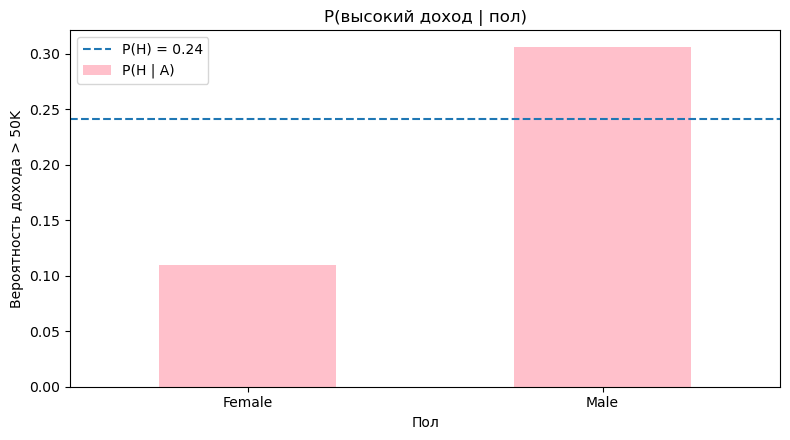

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))

table['P(H | A)'].plot(kind='bar', color='pink', ax=ax)
ax.axhline(P_H, linestyle='--', label=f'P(H) = {P_H:.2f}')
ax.set_title('P(высокий доход | пол)')
ax.set_xlabel('Пол')
ax.set_ylabel('Вероятность дохода > 50K')
ax.tick_params(axis='x', rotation=0)
ax.legend()
plt.tight_layout()
plt.show()

### Напишем функцию определения условных вероятностей
* df - датафрейм
* condition_col - название столбца с произошедшим событием
* target_col - название столбца с целевым событием
* target_val1 - значение первого целевого события
* target_val2 - значение второго целевого события

In [14]:
def conditional_probability(df, condition_col, target_col, target_val1, target_val2):
    rows = []
    for col in df[condition_col].unique():
        p = ((df[condition_col] == col) & (df[target_col] == target_val1)).mean()
        q = ((df[condition_col] == col) & (df[target_col] == target_val2)).mean()
        rows.append({condition_col: col, 'P(A * H)': p, 'P(A * не H)': q})
    
    table = pd.DataFrame(rows).set_index(condition_col)
    
    table['P(A)'] = table['P(A * H)'] + table['P(A * не H)']
    table['P(H | A)'] = table['P(A * H)'] / table['P(A)']
    
    return table

### Для удобства напишем функцию визуализации
* table - таблица с вероятностями, образующими условную вероятность
* col - название события, которое уже произошло

In [15]:
def vis_plot(table, col):
    fig, ax = plt.subplots(figsize=(8, 4.5))

    table['P(H | A)'].plot(kind='bar', color='purple', ax=ax)
    ax.axhline(P_H, linestyle='--', label=f'P(H) = {P_H:.2f}')
    ax.set_title(f'P(высокий доход | {col})')
    ax.set_xlabel(col)
    ax.set_ylabel('Вероятность дохода > 50K')
    ax.tick_params(axis='x', rotation=30)
    ax.legend()
    plt.tight_layout()
    plt.show()

По расе:

                    P(A * H)  P(A * не H)      P(A)  P(H | A)
race                                                         
White               0.218574     0.635699  0.854274  0.255860
Black               0.011885     0.084058  0.095943  0.123880
Asian-Pac-Islander  0.008476     0.023433  0.031909  0.265640
Other               0.000768     0.007555  0.008323  0.092251
Amer-Indian-Eskimo  0.001106     0.008446  0.009551  0.115756


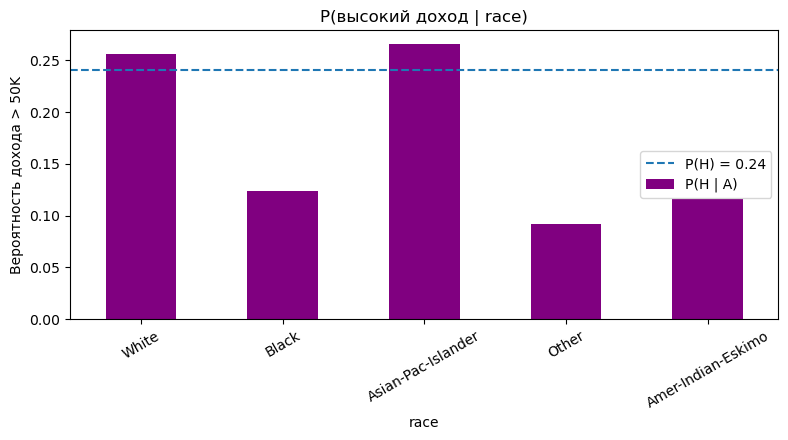

По профессии:

                   P(A * H)  P(A * не H)      P(A)  P(H | A)
occupation                                                  
?                  0.005866     0.050736  0.056601  0.103635
Exec-managerial    0.060440     0.064433  0.124873  0.484014
Machine-op-inspct  0.007678     0.053807  0.061485  0.124875
Prof-specialty     0.057093     0.070053  0.127146  0.449034
Other-service      0.004207     0.096987  0.101195  0.041578
Adm-clerical       0.015571     0.100212  0.115783  0.134483
Craft-repair       0.028531     0.097356  0.125887  0.226641
Transport-moving   0.009828     0.039219  0.049046  0.200376
Handlers-cleaners  0.002641     0.039434  0.042075  0.062774
Sales              0.030189     0.081908  0.112097  0.269315
Farming-fishing    0.003532     0.026995  0.030527  0.115694
Tech-support       0.008691     0.019809  0.028500  0.304957
Protective-serv    0.006480     0.013452  0.019932  0.325116
Armed-Forces       0.000031     0.000246  0.000276  0.111111
Priv-hous

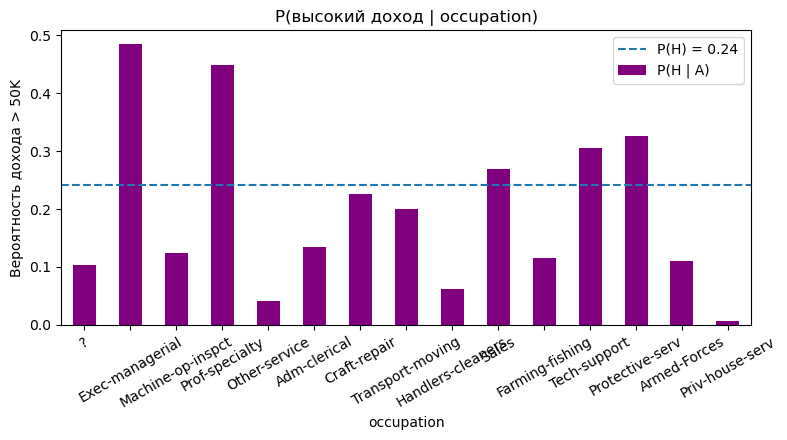

По положению в семье:

                P(A * H)  P(A * не H)      P(A)  P(H | A)
relationship                                             
Not-in-family   0.026289     0.228771  0.255060  0.103070
Unmarried       0.006695     0.099137  0.105832  0.063262
Own-child       0.002058     0.153589  0.155646  0.013220
Other-relative  0.001136     0.028992  0.030128  0.037717
Husband         0.181751     0.223427  0.405178  0.448571
Wife            0.022880     0.025276  0.048156  0.475128


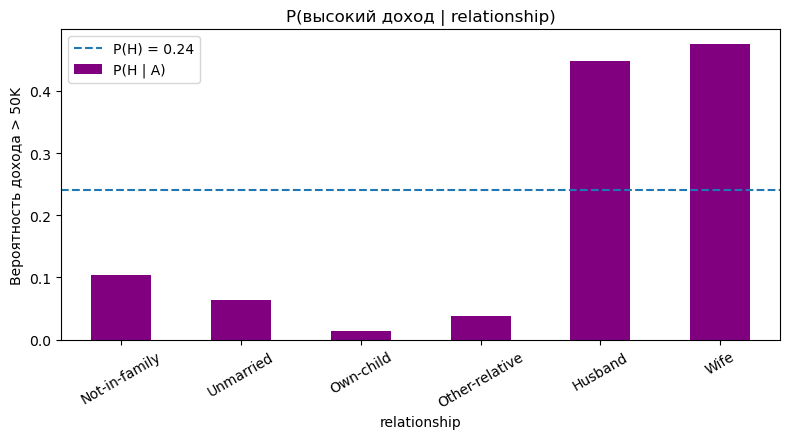

In [16]:
print('По расе:\n')
print('=' * 110)
t = conditional_probability(df, 'race', 'income', '>50K', '<=50K')
print(t)
vis_plot(t, 'race')

print('По профессии:\n')
print('=' * 110)
t = conditional_probability(df, 'occupation', 'income', '>50K', '<=50K')
print(t)
vis_plot(t, 'occupation')

print('По положению в семье:\n')
print('=' * 110)
t = conditional_probability(df, 'relationship', 'income', '>50K', '<=50K')
print(t)
vis_plot(t, 'relationship')

## Формула полной вероятности
$$P(H) = \sum_{i=1}^{n} P_{A_i}(H)\cdot P(A_i).$$

Задача восстановить общую долю людей с высоким доходом, зная только вероятность высокого дохода в каждой группе по образованию и размеры самих групп.

In [51]:
P_A = df['edu_cat'].value_counts() / len(df)
P_HA = (df['income'] == '>50K').groupby(df['edu_cat']).mean()
new_P_H = (P_A * P_HA)
P_H_total = new_P_H.sum()
print(f"P(H) по формуле полной вероятности: {P_H_total}")
print(f"P(H) напрямую из данных:           {P_H}")
print("Совпадают:", P_H == P_H_total)

P(H) по формуле полной вероятности: 0.2408095574460244
P(H) напрямую из данных:           0.2408095574460244
Совпадают: True


C:\Users\Art\AppData\Local\Temp\ipykernel_8448\3832866891.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  P_HA = (df['income'] == '>50K').groupby(df['edu_cat']).mean()


### Визуализация вклада

                      P(A)  P(H | A)  P(A) * P(H | A)
edu_cat                                              
неполное среднее  0.130616  0.057371         0.007494
среднее           0.322502  0.159509         0.051442
колледж           0.299131  0.206674         0.061822
бакалавр          0.164461  0.414753         0.068210
магистр и выше    0.083290  0.622419         0.051841


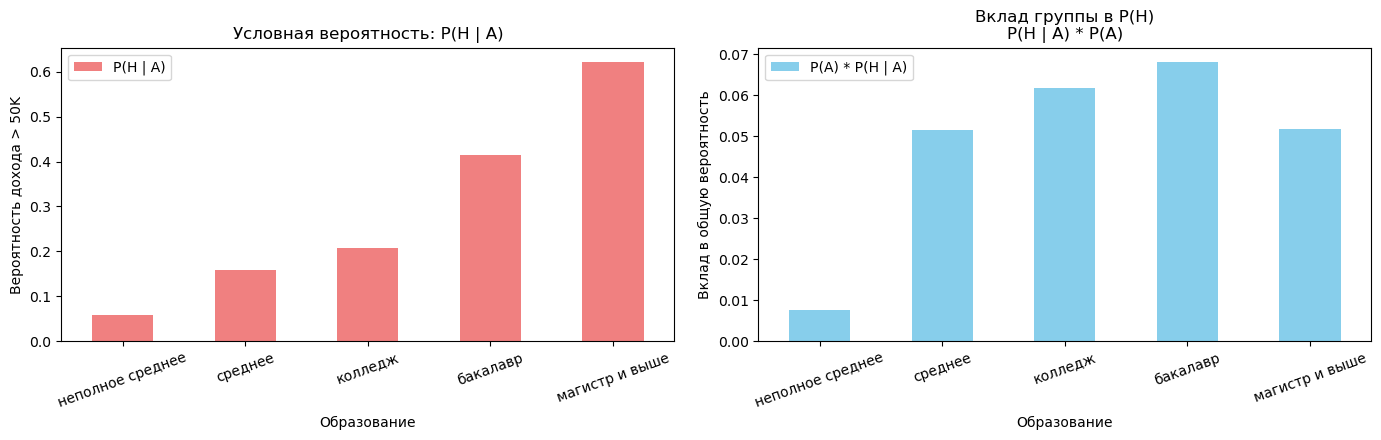

In [18]:
table = pd.DataFrame({'P(A)': P_A, 'P(H | A)': P_HA, 'P(A) * P(H | A)': new_P_H})

print(table)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

table.plot(y='P(H | A)', kind='bar', ax=ax1, color='lightcoral')
ax1.set_title('Условная вероятность: P(H | A)')
ax1.set_xlabel('Образование')
ax1.set_ylabel('Вероятность дохода > 50K')
ax1.tick_params(axis='x', rotation=20)

table.plot(y='P(A) * P(H | A)', kind='bar', ax=ax2, color='skyblue')
ax2.set_title('Вклад группы в P(H)\nP(H | A) * P(A)')
ax2.set_xlabel('Образование')
ax2.set_ylabel('Вклад в общую вероятность')
ax2.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

## Формула Байеса
$$P_{A_i}(H) = \frac{P_{H}(A_i)\cdot P(H)}{P(A_i)}, \qquad P(A_i) = P_{H}(A_i)P(H) + P_{\overline{H}}(A_i)P(\overline{H}).$$
Задача: мы знаем, что человек зарабатывает больше 50K, что можно сказать о его образовании; и наоборот: как, зная образование, пересмотреть вероятность высокого дохода.

In [62]:
edu = ['неполное среднее', 'среднее', 'колледж', 'бакалавр', 'магистр и выше']
P_AH = df.loc[df['income'] == '>50K', 'edu_cat'].value_counts(normalize=True).reindex(edu)

bayes = P_AH * P_H / P_A
table_bayes = pd.DataFrame({'P(H)': P_H,'P(A)': P_A, 'P(A | H)': P_AH, 'P(H | A) через Байеса': bayes, 'P(H | A) напрямую': P_HA, \
                            'Совпадают': np.isclose(table_bayes['P(H | A) через Байеса'], table_bayes['P(H | A) напрямую'])})
table_bayes

,P(H),P(A),P(A | H),P(H | A) через Байеса,P(H | A) напрямую,Совпадают
edu_cat,,,,,,
бакалавр,0.24081,0.164461,0.283255,0.414753,0.414753,True
колледж,0.24081,0.299131,0.256727,0.206674,0.206674,True
магистр и выше,0.24081,0.083290,0.215279,0.622419,0.622419,True
неполное среднее,0.24081,0.130616,0.031118,0.057371,0.057371,True
среднее,0.24081,0.322502,0.213621,0.159509,0.159509,True


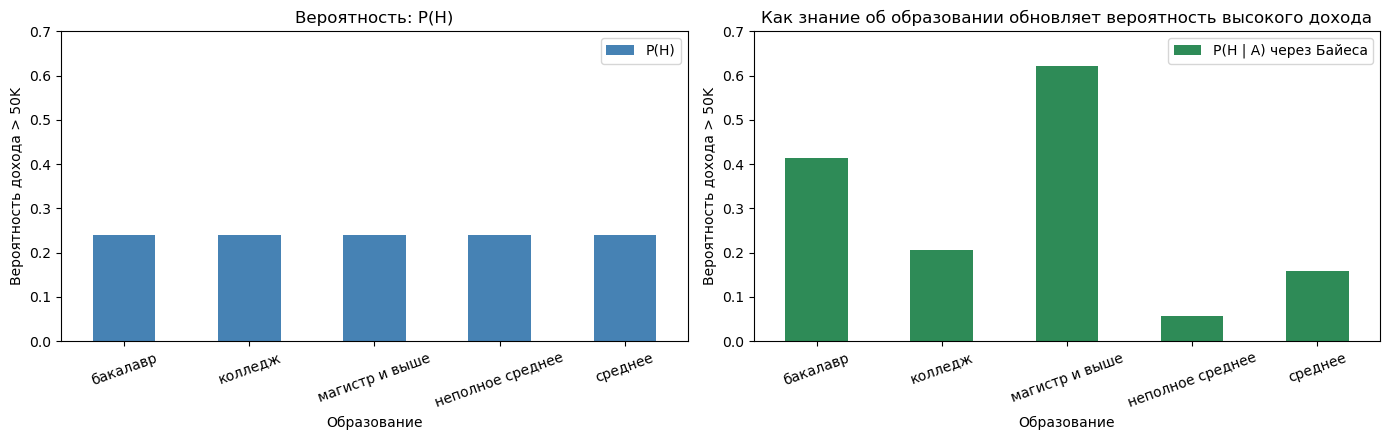

In [67]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

table_bayes.plot(y='P(H)', kind='bar', ax=ax1, color='steelblue')
ax1.set_title('Вероятность: P(H)')
ax1.set_xlabel('Образование')
ax1.set_ylabel('Вероятность дохода > 50K')
ax1.tick_params(axis='x', rotation=20)
ax1.set_ylim(0, 0.7)

table_bayes.plot(y='P(H | A) через Байеса', kind='bar', ax=ax2, color='seagreen')
ax2.set_title('Как знание об образовании обновляет вероятность высокого дохода')
ax2.set_xlabel('Образование')
ax2.set_ylabel('Вероятность дохода > 50K')
ax2.tick_params(axis='x', rotation=20)
ax2.set_ylim(0, 0.7)

plt.tight_layout()
plt.show()

### Наоборот сравним вероятность того или иного образования с вероятностью того или иного образования, но с учетом высокого дохода

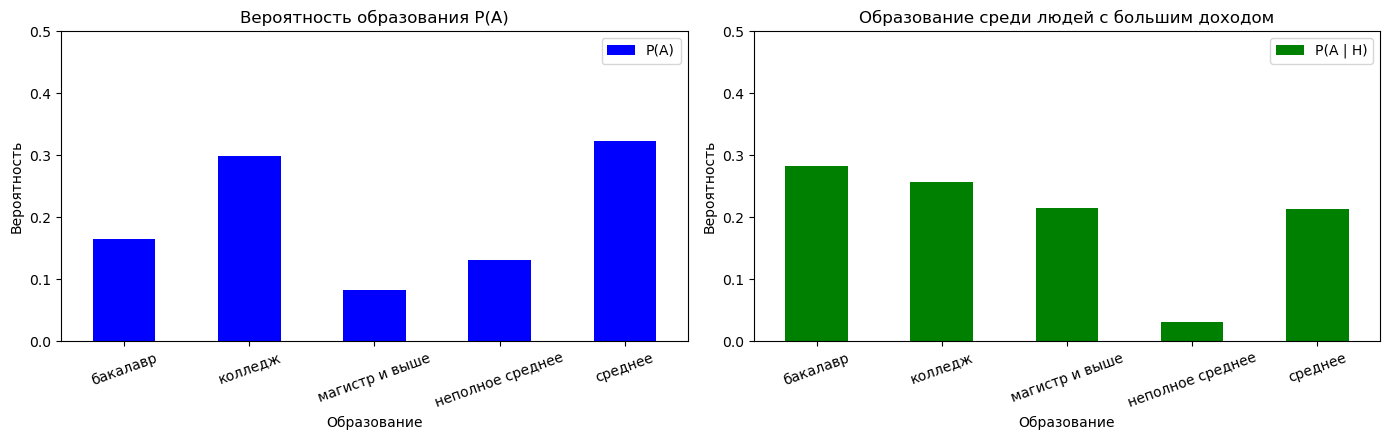

In [73]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

table_bayes.plot(y='P(A)', kind='bar', ax=ax1, color='blue')
ax1.set_title('Вероятность образования P(A)')
ax1.set_xlabel('Образование')
ax1.set_ylabel('Вероятность')
ax1.tick_params(axis='x', rotation=20)
ax1.set_ylim(0, 0.5)

table_bayes.plot(y='P(A | H)', kind='bar', ax=ax2, color='green')
ax2.set_title('Образование среди людей с большим доходом')
ax2.set_xlabel('Образование')
ax2.set_ylabel('Вероятность')
ax2.tick_params(axis='x', rotation=20)
ax2.set_ylim(0, 0.5)

plt.tight_layout()
plt.show()